In [12]:
from langgraph.graph import StateGraph, MessagesState, START, END
from typing import TypedDict,Annotated
from langchain_google_genai import ChatGoogleGenerativeAI
from dotenv import load_dotenv
from pydantic import BaseModel, Field
import operator
from langchain_core.prompts import PromptTemplate

load_dotenv()   

True

In [13]:
llm = ChatGoogleGenerativeAI(model="gemini-3.7-flash")

In [14]:
class EssayState(TypedDict):
    essay:str
    language_feedback: str
    analysis_feedback: str
    clarity_feedback: str
    overall_feedback: str
    Scores:Annotated[list[int], operator.add]
    avg_score: float

In [15]:
class LanguageEvaluation(BaseModel):
    eval: str = Field(description="Concise feedback on language quality")
    score: int = Field(description="Language quality score out of 10")


structured_llm = llm.with_structured_output(LanguageEvaluation)


def eval_lang(state: EssayState):
    essay = state["essay"]
    prompt = f"""
    Evaluate the following essay paragraph ONLY for language quality.
    Check vocabulary choice, sentence variety, and academic tone.
    Do NOT judge the ideas, arguments, facts, or content.
    Essay:
    {essay}
    Be very honest and concise. Give a score out of 10.
    """
    result = structured_llm.invoke(prompt)
    return {"language_feedback": result.eval, "Scores": result.score}

In [16]:
class GrammarEvaluation(BaseModel):
    eval: str = Field(description="Concise feedback on language quality")
    score: int = Field(description="Language quality score out of 10")
    
structured_llm = llm.with_structured_output(GrammarEvaluation)

def Grammar_eval(state: EssayState):
    essay = state['essay']

    prompt = f"""
    Evaluate the following essay paragraph ONLY for Grammar quality.
    Essay:
    {essay}

    Be very honest and concise. Give a score out of 10.
    """

    result = structured_llm.invoke(prompt)

    return {
        "clarity_feedback": result.eval,
        "Scores": result.score
    }

In [17]:
class Spelling(BaseModel):
    eval: str = Field(description="Concise feedback on language quality")
    score: int = Field(description="Language quality score out of 10")


structured_llm = llm.with_structured_output(Spelling)


def eval_Spelling(state: EssayState):
    essay = state['essay']

    prompt = f"""
    Evaluate the following essay paragraph ONLY for spelling correctness.
    Essay:
    {essay}

    Be very honest and concise. Give a score out of 10.
    """

    result = structured_llm.invoke(prompt)

    return {"Spelling": result.eval, "Scores": result.score}

In [18]:
class OverEvalation(BaseModel):
    eval:str=Field(description='give overall idea of how the quality of eassy is like is it to the point')
    
structured_llm = llm.with_structured_output(OverEvalation)

def over_eval(state:EssayState):
    essay = state["essay"]
    prompt="be hontst and rate this essay"
    result=structured_llm.invoke(prompt)
    avg_score= sum(state['Scores'])/len(state['Scores'])
    return {'avg_score':avg_score,'overall_feedback':result}

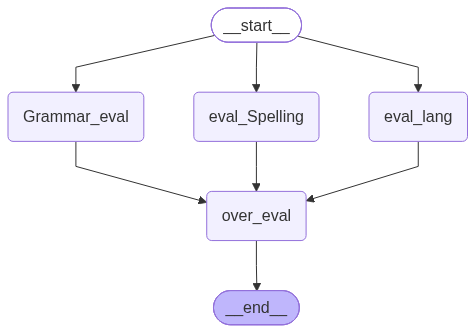

In [20]:
graph=StateGraph(EssayState)

graph.add_node('eval_lang',eval_lang)
graph.add_node('Grammar_eval',Grammar_eval)
graph.add_node('eval_Spelling',eval_Spelling)
graph.add_node('over_eval',over_eval)

graph.add_edge(START,'eval_lang')
graph.add_edge(START,'Grammar_eval')
graph.add_edge(START,'eval_Spelling')
graph.add_edge('eval_lang','over_eval')
graph.add_edge('Grammar_eval','over_eval')
graph.add_edge('eval_Spelling','over_eval')

graph.add_edge('over_eval', END)

workflow=graph.compile()

workflow